# 🎯 K-Means Clustering from Scratch

**Goal:** Partition $m$ unlabelled examples into $K$ clusters so that points within a cluster are closer to each other than to points in other clusters.

---

## 1. Algorithm Intuition

K-Means alternates between two steps until convergence:

**Step 1 — Assignment (E-step):** Assign every point to the nearest centroid.

$$c^{(i)} = \arg\min_{k} \| \mathbf{x}^{(i)} - \boldsymbol{\mu}_k \|^2$$

**Step 2 — Update (M-step):** Move each centroid to the mean of all its assigned points.

$$\boldsymbol{\mu}_k = \frac{1}{|C_k|} \sum_{i \in C_k} \mathbf{x}^{(i)}$$

**Objective function** (within-cluster sum of squared distances, WCSS):

$$J = \sum_{k=1}^{K} \sum_{i \in C_k} \| \mathbf{x}^{(i)} - \boldsymbol{\mu}_k \|^2$$

K-Means is **guaranteed to converge** (J is non-increasing) but may find a local minimum depending on initialisation.

**Variable glossary:**
| Symbol | Meaning |
|--------|---------|
| $K$ | number of clusters |
| $\boldsymbol{\mu}_k$ | centroid of cluster $k$ |
| $c^{(i)}$ | cluster assignment of example $i$ |
| $C_k$ | set of example indices assigned to cluster $k$ |
| $J$ | WCSS distortion cost |

---

## 2. Initialisation

We implement **K-Means++** initialisation, which spreads initial centroids far apart to avoid poor local minima:
1. Choose the first centroid uniformly at random.
2. Each subsequent centroid is chosen from the data with probability proportional to its squared distance from the nearest already-chosen centroid.


## 3. Imports

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)
plt.style.use('seaborn-v0_8-whitegrid')

## 4. Synthetic Blob Data (No Labels Used)

In [2]:
def make_blobs(n_per_cluster, centers, std=0.7, seed=42):
    rng = np.random.default_rng(seed)
    X_list, y_list = [], []
    for label, center in enumerate(centers):
        pts = rng.normal(loc=center, scale=std, size=(n_per_cluster, 2))
        X_list.append(pts)
        y_list.append(np.full(n_per_cluster, label))
    X = np.vstack(X_list)
    y = np.hstack(y_list)
    perm = rng.permutation(len(y))
    return X[perm], y[perm]

true_centers = [(-4, 0), (0, 4), (4, 0), (0, -4)]
K_true = len(true_centers)

X, y_true = make_blobs(n_per_cluster=80, centers=true_centers)

# K-Means is unsupervised — we NEVER use y_true during training
print(f"X shape: {X.shape}")
print("(y_true is kept only for evaluation — not used in training)")

X shape: (320, 2)
(y_true is kept only for evaluation — not used in training)


In [3]:
# Normalise features — good practice for distance-based methods
mu_X    = X.mean(axis=0)
sigma_X = X.std(axis=0)
sigma_X[sigma_X == 0] = 1
X_n = (X - mu_X) / sigma_X
print(f"Normalised X mean ≈ {X_n.mean():.4f}, std ≈ {X_n.std():.4f}")

Normalised X mean ≈ 0.0000, std ≈ 1.0000


## 5. K-Means++ Initialisation

In [4]:
def kmeans_plus_plus_init(X, K, seed=42):
    """
    Initialise K centroids using the K-Means++ algorithm.

    Returns
    -------
    centroids : ndarray (K, n)
    """
    rng = np.random.default_rng(seed)
    m   = X.shape[0]

    # Step 1: choose first centroid uniformly at random
    centroids = [X[rng.integers(m)]]

    for _ in range(K - 1):
        # Step 2: for each point, find squared distance to the nearest centroid
        sq_dists = np.array([
            min(np.sum((x - c) ** 2) for c in centroids)
            for x in X
        ])
        # Choose next centroid with probability proportional to sq_dists
        probs  = sq_dists / sq_dists.sum()
        cumprob = np.cumsum(probs)
        r      = rng.random()
        idx    = np.searchsorted(cumprob, r)
        centroids.append(X[idx])

    return np.array(centroids)

## 6. Assignment Step

In [5]:
def assign_clusters(X, centroids):
    """
    Assign each point to the nearest centroid.

    c^(i) = argmin_k  ||x^(i) - mu_k||^2

    Returns
    -------
    assignments : ndarray (m,) — cluster index for each point
    """
    K = centroids.shape[0]
    m = X.shape[0]

    # sq_dists[i, k] = squared Euclidean distance from point i to centroid k
    sq_dists = np.zeros((m, K))
    for k in range(K):
        diff          = X - centroids[k]    # broadcast: (m, n) - (n,)
        sq_dists[:, k] = np.sum(diff ** 2, axis=1)

    assignments = np.argmin(sq_dists, axis=1)   # shape (m,)
    return assignments

## 7. Update Step

In [6]:
def update_centroids(X, assignments, K):
    """
    Move each centroid to the mean of its assigned points.

    mu_k = (1/|C_k|) * sum_{i in C_k} x^(i)

    If a centroid has no assigned points, it stays at its previous position
    (handled by keeping the old centroid value — not possible here since
    we always pass previous centroids for that edge case).

    Returns
    -------
    new_centroids : ndarray (K, n)
    """
    n = X.shape[1]
    new_centroids = np.zeros((K, n))
    for k in range(K):
        points_in_k = X[assignments == k]
        if len(points_in_k) == 0:
            # Edge case: empty cluster — keep old centroid (caller passes previous)
            continue
        new_centroids[k] = points_in_k.mean(axis=0)
    return new_centroids

## 8. WCSS Distortion

In [7]:
def compute_wcss(X, assignments, centroids):
    """
    WCSS = sum over all clusters of sum of squared distances to centroid.
    """
    wcss = 0.0
    for k in range(centroids.shape[0]):
        pts  = X[assignments == k]
        diff = pts - centroids[k]
        wcss += np.sum(diff ** 2)
    return wcss

## 9. Full K-Means Loop

In [8]:
def kmeans(X, K, max_iters=100, tol=1e-6, seed=42):
    """
    Run K-Means clustering.

    Parameters
    ----------
    X        : ndarray (m, n)
    K        : int — number of clusters
    max_iters: int — maximum iterations
    tol      : float — convergence tolerance (centroid movement)
    seed     : int

    Returns
    -------
    centroids   : ndarray (K, n) — final cluster centres
    assignments : ndarray (m,)   — cluster label per point
    J_history   : list[float]    — WCSS per iteration
    """
    centroids   = kmeans_plus_plus_init(X, K, seed=seed)
    J_history   = []

    for i in range(max_iters):
        old_centroids = centroids.copy()

        # Assignment step
        assignments = assign_clusters(X, centroids)

        # Update step
        new_centroids = update_centroids(X, assignments, K)

        # Handle empty clusters: keep old centroid
        for k in range(K):
            if np.sum(assignments == k) == 0:
                new_centroids[k] = old_centroids[k]

        centroids  = new_centroids
        wcss       = compute_wcss(X, assignments, centroids)
        J_history.append(wcss)

        # Check convergence: max centroid shift < tol
        shift = np.max(np.linalg.norm(centroids - old_centroids, axis=1))
        if shift < tol:
            print(f"Converged at iteration {i + 1}  (centroid shift={shift:.2e})")
            break

    return centroids, assignments, J_history

## 10. Fit the Model

In [9]:
K = 4
centroids, assignments, J_history = kmeans(X_n, K=K, max_iters=100, seed=42)
print(f"WCSS after convergence: {J_history[-1]:.4f}")

Converged at iteration 2  (centroid shift=0.00e+00)
WCSS after convergence: 35.0329


## 11. Visualisations

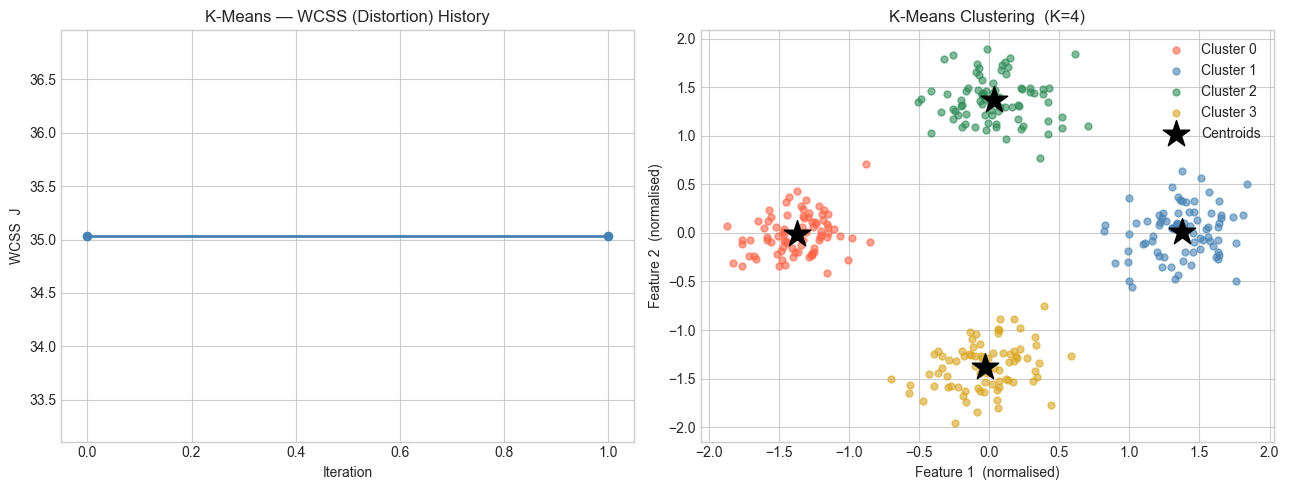

In [10]:
palette = ['tomato', 'steelblue', 'seagreen', 'goldenrod']

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# --- WCSS / cost history ---
axes[0].plot(J_history, marker='o', color='steelblue', linewidth=2)
axes[0].set_xlabel('Iteration')
axes[0].set_ylabel('WCSS  J')
axes[0].set_title('K-Means — WCSS (Distortion) History')

# --- Cluster assignments ---
for k in range(K):
    mask = assignments == k
    axes[1].scatter(X_n[mask, 0], X_n[mask, 1],
                    color=palette[k], alpha=0.6, s=25, label=f'Cluster {k}')
axes[1].scatter(centroids[:, 0], centroids[:, 1],
                marker='*', s=400, color='black', zorder=5, label='Centroids')
axes[1].set_xlabel('Feature 1  (normalised)')
axes[1].set_ylabel('Feature 2  (normalised)')
axes[1].set_title(f'K-Means Clustering  (K={K})')
axes[1].legend()

plt.tight_layout()
plt.show()

## 12. Elbow Method — Choosing K

Converged at iteration 2  (centroid shift=0.00e+00)
  K=1  →  WCSS=640.00
Converged at iteration 8  (centroid shift=0.00e+00)
  K=2  →  WCSS=327.62
Converged at iteration 5  (centroid shift=0.00e+00)
  K=3  →  WCSS=181.09
Converged at iteration 2  (centroid shift=0.00e+00)
  K=4  →  WCSS=35.03
Converged at iteration 7  (centroid shift=0.00e+00)
  K=5  →  WCSS=31.24
Converged at iteration 11  (centroid shift=0.00e+00)
  K=6  →  WCSS=27.86
Converged at iteration 8  (centroid shift=0.00e+00)
  K=7  →  WCSS=26.13
Converged at iteration 12  (centroid shift=0.00e+00)
  K=8  →  WCSS=23.23
Converged at iteration 8  (centroid shift=0.00e+00)
  K=9  →  WCSS=22.37


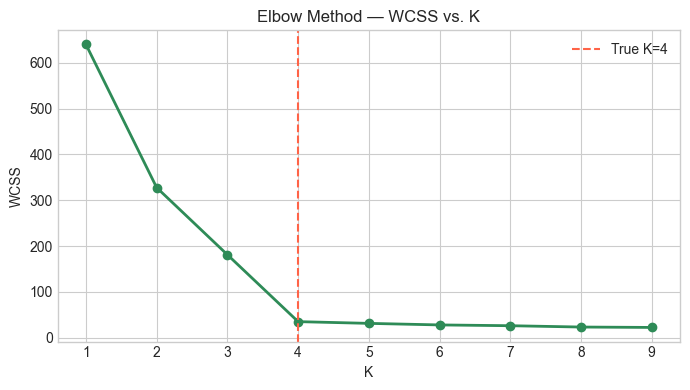

In [11]:
k_values = range(1, 10)
wcss_by_k = []

for k in k_values:
    c, a, j = kmeans(X_n, K=k, max_iters=100, seed=42)
    wcss_by_k.append(j[-1])
    print(f"  K={k}  →  WCSS={j[-1]:.2f}")

plt.figure(figsize=(7, 4))
plt.plot(list(k_values), wcss_by_k, marker='o', color='seagreen', linewidth=2)
plt.axvline(K_true, color='tomato', linestyle='--', linewidth=1.5,
            label=f'True K={K_true}')
plt.xlabel('K')
plt.ylabel('WCSS')
plt.title('Elbow Method — WCSS vs. K')
plt.legend()
plt.tight_layout()
plt.show()

## 13. Evaluation — Purity Score

Since we generated synthetic data with known labels, we can measure **cluster purity** — the fraction of dominant-class points in each cluster.

In [12]:
def cluster_purity(y_true, assignments, K):
    """
    Purity = (1/m) * sum_k max_c |cluster_k ∩ class_c|

    A purity of 1.0 means each cluster contains only one class.
    """
    m = len(y_true)
    total_correct = 0
    for k in range(K):
        labels_in_k = y_true[assignments == k]
        if len(labels_in_k) == 0:
            continue
        _, counts = np.unique(labels_in_k, return_counts=True)
        total_correct += counts.max()
    return total_correct / m

purity = cluster_purity(y_true, assignments, K)
print(f"Cluster Purity: {purity:.4f}")

Cluster Purity: 1.0000


## 14. Observations and Limitations

### What we observed
- WCSS decreases monotonically — K-Means is guaranteed to reduce (or keep) distortion each iteration.
- The Elbow method shows a clear kink at $K=4$, matching the true number of clusters.
- K-Means++ initialisation finds good centroids and converges quickly.

### Limitations
| Limitation | Description |
|------------|-------------|
| **Must specify K** | The number of clusters must be chosen in advance. |
| **Spherical clusters only** | Assumes equal-variance, blob-shaped clusters. |
| **Sensitive to outliers** | A single outlier can pull a centroid far away. |
| **Local minima** | Different initialisations can give different solutions. |
| **Not for arbitrary shapes** | Cannot detect elongated, ring-shaped, or density-varying clusters (DBSCAN handles these). |
